#Import Data

In [1]:
!pip install fredapi
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from google.colab import userdata
from fredapi import Fred

api_key = userdata.get('FRED_API_KEY')
fred = Fred(api_key=api_key)

In [3]:
fed_funds = fred.get_series('FEDFUNDS')

savings_rate = fred.get_series('PSAVERT')

m2 = fred.get_series('M2SL')

#national average savings deposit rate
deposit_rate = fred.get_series('SNDR')

#Clean Data

In [4]:
#Dataframe including deposit rate (limits data range to start in 2021)
df = pd.DataFrame({
    'fed_funds': fed_funds,
    'savings_rate': savings_rate,
    'm2': m2, 'deposit_rate': deposit_rate
    })

df = df.dropna()

In [5]:
#Dataframe excluding deposit rate (full data range)
df2 = pd.DataFrame({
    'fed_funds': fed_funds,
    'savings_rate': savings_rate,
    'm2': m2
    })

df2 = df2.dropna()

#Fed Funds Rate vs Personal Savings Rate

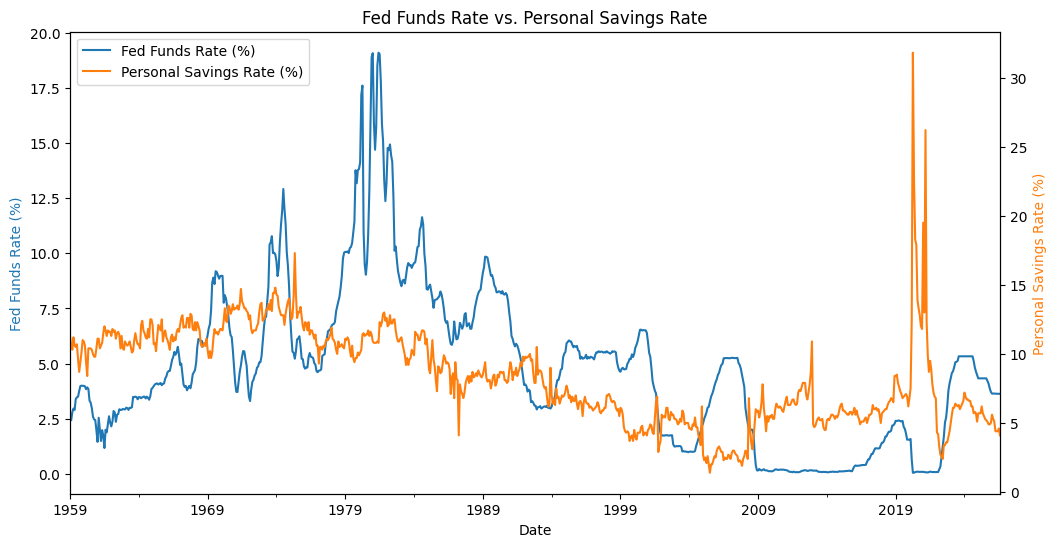

In [6]:
ax = df2['fed_funds'].plot(figsize=(12, 6), color='tab:blue', label='Fed Funds Rate (%)')
df2['savings_rate'].plot(ax=ax, secondary_y=True, color='tab:orange', label='Personal Savings Rate (%)')

ax.set_xlabel('Date')
ax.set_ylabel('Fed Funds Rate (%)', color='tab:blue')
ax.right_ax.set_ylabel('Personal Savings Rate (%)', color='tab:orange')

ax.set_title('Fed Funds Rate vs. Personal Savings Rate')

# Combine legends from both axes into one
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax.right_ax.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

# Strip the auto-added suffix for secondary axis label
labels2 = [label.replace(' (right)', '') for label in labels2]
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()

In [7]:
#Raw coorelation between fed funds rate and savings rate
correlation = df2['fed_funds'].corr(df2['savings_rate'])
print(f"Correlation between Fed Funds Rate and Personal Savings Rate: {correlation:.3f}")

#Coorelation of m/m change of fed funds rate and savings rate
df2_changes = df2.diff().dropna()
change_correlation = df2_changes['fed_funds'].corr(df2_changes['savings_rate'])
print(f"Correlation of month-over-month changes: {change_correlation:.3f}")

Correlation between Fed Funds Rate and Personal Savings Rate: 0.367
Correlation of month-over-month changes: -0.047


In [8]:
for lag in [1, 3, 6, 12]:
       lagged_corr = df2_changes['fed_funds'].corr(df2_changes['savings_rate'].shift(-lag))
       print(f"Lag {lag} months: {lagged_corr:.3f}")

Lag 1 months: -0.002
Lag 3 months: 0.015
Lag 6 months: 0.005
Lag 12 months: -0.010


#Fed Funds Rate vs M2

In [9]:
#Raw coorelation between fed funds rate and M2
m2_level_corr = df2['fed_funds'].corr(df2['m2'])
print(f"Correlation between Fed Funds Rate and M2: {m2_level_corr:.3f}")

#Coorelation of m/m change of fed funds rate and M2
m2_change_corr = df2_changes['fed_funds'].corr(df2_changes['m2'])
print(f"Correlation of month-over-month changes: {m2_change_corr:.3f}")

Correlation between Fed Funds Rate and M2: -0.469
Correlation of month-over-month changes: -0.083


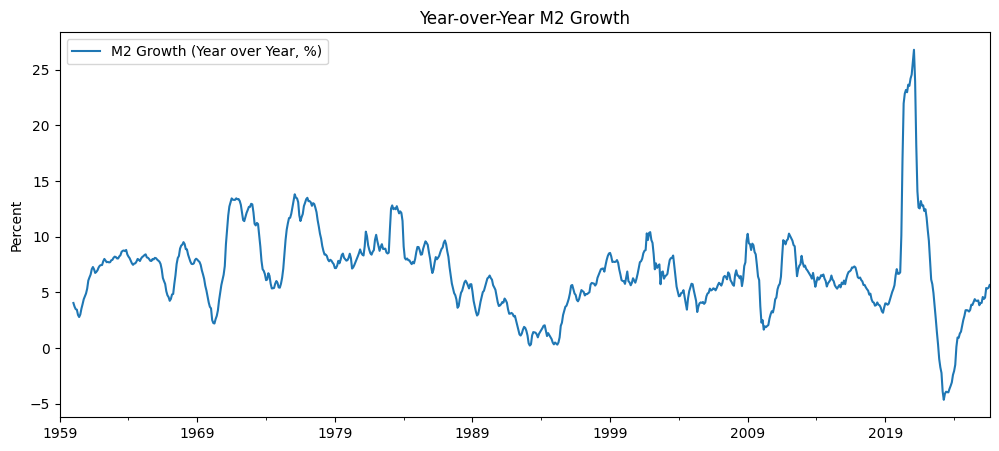

Correlation between Fed funds rate and M2 growth: 0.014


In [10]:
# Year-over-year percentage growth in M2
df2['m2_yoy_growth'] = df2['m2'].pct_change(12) * 100

ax = df2['m2_yoy_growth'].plot(
    figsize=(12, 5),
    label='M2 Growth (Year over Year, %)'
)
ax.set_title('Year-over-Year M2 Growth')
ax.set_ylabel('Percent')
ax.legend()
plt.show()

print(
    'Correlation between Fed funds rate and M2 growth:',
    round(df2['fed_funds'].corr(df2['m2_yoy_growth']), 3)
)

#Fed Funds Rate vs Savings Deposit Rate

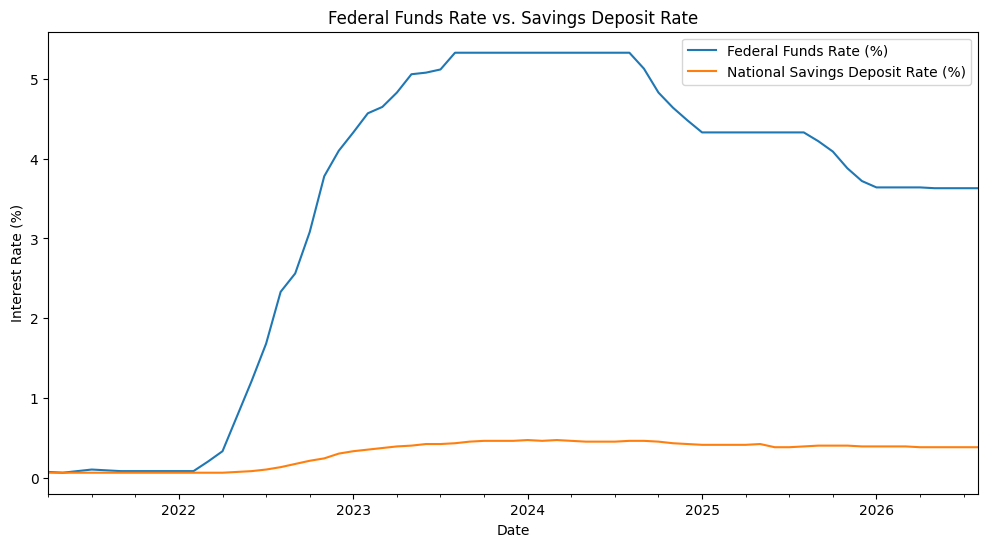

Average spread: 3.11 percent
Maximum spread: 4.9 percent
Minimum spread: 0.0 percent


In [11]:
# Difference between Fed funds and savings deposit rates
df['deposit_spread'] = df['fed_funds'] - df['deposit_rate']

# Plot Fed funds vs. bank deposit rates
ax = df['fed_funds'].plot(
    figsize=(12, 6),
    label='Federal Funds Rate (%)'
)

df['deposit_rate'].plot(
    ax=ax,
    label='National Savings Deposit Rate (%)'
)

ax.set_title('Federal Funds Rate vs. Savings Deposit Rate')
ax.set_ylabel('Interest Rate (%)')
ax.set_xlabel('Date')
ax.legend()
plt.show()

print("Average spread:", round(df['deposit_spread'].mean(), 2), "percent")
print("Maximum spread:", round(df['deposit_spread'].max(), 2), "percent")
print("Minimum spread:", round(df['deposit_spread'].min(), 2), "percent")

In [12]:
# Month-over-month changes
df_changes = df[['fed_funds', 'deposit_rate',
                 'savings_rate', 'm2']].diff()

# Correlation between Fed rate changes and
# subsequent deposit rate changes
for lag in [0, 1, 3, 6, 12]:
    corr = (
        df_changes['fed_funds']
        .corr(df_changes['deposit_rate'].shift(-lag))
    )
    print(f"Deposit rate change after {lag} months: {corr:.3f}")

Deposit rate change after 0 months: 0.669
Deposit rate change after 1 months: 0.815
Deposit rate change after 3 months: 0.675
Deposit rate change after 6 months: 0.527
Deposit rate change after 12 months: 0.038
